# Cleaning dataset

Let's first load, inspect and clean the data

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

DATA_DIR = "sample_data"  

In [ ]:
## check if we got all the files, should have 2 per year - now its just one
files = sorted(glob.glob(os.path.join(DATA_DIR, "jena*.csv*")))
print(len(files), "files found:")
for f in files:
    print(" ", os.path.basename(f))

1 files found:
  jena_climate_2009_2016.csv


In [3]:
# look at one of the files to see its shape and columns
sample = pd.read_csv(files[0])
print(sample.shape)
print(sample.columns.tolist())
sample.head()

(420551, 15)
['Date Time', 'p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


In [ ]:
# fuse the code tghter

# parse thru all the files and append - this was needed when we had 16 separate files
dfs = []
for f in files:
    part = pd.read_csv(f)
    part["source_file"] = os.path.basename(f)   # to debugging
    dfs.append(part)

# fuse all data tgether - not needed anymore
df = pd.concat(dfs, ignore_index=True)

# get date time column into datatime format. clean up errors
df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S", errors="coerce")

# sort chronologically
df = df.sort_values("Date Time").reset_index(drop=True)

# Remove duplicates, can occur at start and end of file
n_before = len(df)
df = df.drop_duplicates(subset="Date Time", keep="first").reset_index(drop=True)
print(f"Dropped {n_before - len(df)} duplicate timestamps")

print("Shape:", df.shape)
print("Date range:", df["Date Time"].min(), "->", df["Date Time"].max())
print("Unparsed dates:", df["Date Time"].isna().sum())

Dropped 327 duplicate timestamps
Shape: (420224, 16)
Date range: 2009-01-01 00:10:00 -> 2017-01-01 00:00:00
Unparsed dates: 0


According to the TA: "To get the hourly version described in the assignment, keep every sixth row, starting from the 01:00 reading on 1 January 2009. "

In [ ]:
# check if 1:00 from 1 jan 2009
print(df["Date Time"].head(7))

# get every 6th row
df = df.iloc[5::6].reset_index(drop=True)

# round to closest min
df["Date Time"] = df["Date Time"].dt.round("min")

print("Hourly shape:", df.shape)               
print("First row:", df["Date Time"].iloc[0])   

0   2009-01-01 00:10:00
1   2009-01-01 00:20:00
2   2009-01-01 00:30:00
3   2009-01-01 00:40:00
4   2009-01-01 00:50:00
5   2009-01-01 01:00:00
6   2009-01-01 01:10:00
Name: Date Time, dtype: datetime64[us]
Hourly shape: (70037, 16)
First row: 2009-01-01 01:00:00


ltsm requires that its data tiem are linear in time. That means if there are some gaps in irregular time stamps, it could cause issues. The model odesnt necessarily know that more time has passed between the two points.

One way to solve it is to interpolate a value, but assignemtn removes points if there's data leakage or such things.

We can thus drop some sliding windows over these areas. Since there are not that many gaps we are not losing much traning data.

In [7]:
dt = df["Date Time"].diff().dropna()
print("Time step counts:")
print(dt.value_counts().head())

# Locate any gaps (anything other than 1 hour)
gaps = df.loc[dt[dt != pd.Timedelta(hours=1)].index, ["Date Time", "source_file"]]
gaps["gap_size"] = dt[dt != pd.Timedelta(hours=1)]
print("\nGaps found:", len(gaps))
print(gaps.head(20))

Time step counts:
Date Time
0 days 01:00:00    70031
0 days 01:10:00        2
0 days 01:20:00        1
0 days 16:50:00        1
3 days 03:10:00        1
Name: count, dtype: int64

Gaps found: 5
                Date Time                 source_file        gap_size
6729  2009-10-08 10:20:00  jena_climate_2009_2016.csv 0 days 01:20:00
38312 2013-05-16 09:30:00  jena_climate_2009_2016.csv 0 days 01:10:00
48871 2014-07-30 08:40:00  jena_climate_2009_2016.csv 0 days 01:10:00
50224 2014-09-25 09:30:00  jena_climate_2009_2016.csv 0 days 16:50:00
68490 2016-10-28 13:40:00  jena_climate_2009_2016.csv 3 days 03:10:00


for each gap that we drop, we add a segment ID (a segment consists of a bunch of non interrupted data)

In [8]:
# new segment id every time the time step isnt 1 hours
df["segment"] = (df["Date Time"].diff() != pd.Timedelta(hours=1)).cumsum()
print("Number of continuous segments:", df["segment"].nunique())
print(df.groupby("segment").size().describe())

Number of continuous segments: 6
count        6.000000
mean     11672.833333
std      11615.491008
min       1353.000000
25%       2842.500000
50%       8644.000000
75%      16339.250000
max      31583.000000
dtype: float64


In [9]:
def make_windows(data, feature_cols, target_cols, k):
    """
    data: DataFrame with a 'segment' column, sorted by time.
    Returns X of shape (N, k, n_features) and y of shape (N, n_targets).
    No window crosses a gap, because each is built inside one segment.
    """
    X_list, y_list = [], []
    for _, seg in data.groupby("segment"):
        if len(seg) <= k:          # segment too short to form even one window
            continue
        feats = seg[feature_cols].to_numpy(dtype=np.float32)
        targs = seg[target_cols].to_numpy(dtype=np.float32)
        for i in range(k, len(seg)):
            X_list.append(feats[i - k:i])   # rows t-k ... t-1
            y_list.append(targs[i])          # row t
    return np.stack(X_list), np.stack(y_list)

check missing values and any wrong data

In [10]:
print("Missing values per column:")
print(df.isna().sum())

pd.set_option("display.width", 200)
df.describe().T

Missing values per column:
Date Time          0
p (mbar)           0
T (degC)           0
Tpot (K)           0
Tdew (degC)        0
rh (%)             0
VPmax (mbar)       0
VPact (mbar)       0
VPdef (mbar)       0
sh (g/kg)          0
H2OC (mmol/mol)    0
rho (g/m**3)       0
wv (m/s)           0
max. wv (m/s)      0
wd (deg)           0
source_file        0
segment            0
dtype: int64


,count,mean,min,25%,50%,75%,max,std
Date Time,70037,2012-12-30 09:32:40.320973,2009-01-01 01:00:00,2010-12-31 14:20:00,2012-12-30 03:20:00,2014-12-30 08:30:00,2016-12-31 23:40:00,NaN
p (mbar),70037.0,989.213986,913.6,984.21,989.58,994.72,1015.35,8.361265
T (degC),70037.0,9.443924,-22.76,3.35,9.4,15.47,37.1,8.422167
Tpot (K),70037.0,283.486415,250.85,277.43,283.45,289.52,311.04,8.503137
Tdew (degC),70037.0,4.95448,-24.8,0.23,5.21,10.08,23.06,6.73049
rh (%),70037.0,76.02761,13.88,65.23,79.3,89.4,100.0,16.461357
VPmax (mbar),70037.0,13.570414,0.97,7.77,11.81,17.6,63.15,7.736667
VPact (mbar),70037.0,9.532792,0.81,6.21,8.86,12.36,28.25,4.183617
VPdef (mbar),70037.0,4.037556,0.0,0.87,2.19,5.29,45.41,4.893291
sh (g/kg),70037.0,6.021796,0.51,3.92,5.59,7.8,18.07,2.655797


In [11]:
# Known issue in this dataset: wind velocity columns contain -9999 placeholders
wind_cols = [c for c in df.columns if "wv" in c.lower()]
for c in wind_cols:
    print(f"{c}: min={df[c].min():.2f}, count(<0)={(df[c] < 0).sum()}")

# Check the 4 required columns for physically implausible values
target_cols = ["p (mbar)", "T (degC)", "rh (%)", "wv (m/s)"]
for c in target_cols:
    print(f"{c}: min={df[c].min():.2f}, max={df[c].max():.2f}")

wv (m/s): min=-9999.00, count(<0)=3
max. wv (m/s): min=-9999.00, count(<0)=3
p (mbar): min=913.60, max=1015.35
T (degC): min=-22.76, max=37.10
rh (%): min=13.88, max=100.00
wv (m/s): min=-9999.00, max=14.01


In [12]:

# replace anything that's -9999 iwth Nan
for c in target_cols:
    if c == "rh (%)":
        df.loc[df[c] <= 0, c] = np.nan # we cant have humuditiy of 0 or less
    else:
        df.loc[df[c] < -9000, c] = np.nan
# fill using past value. we are not interpolating
df[target_cols] = df[target_cols].ffill()
#print out the max and min of each feature
print(df[target_cols].describe().T[["min", "max"]])



             min      max
p (mbar)  913.60  1015.35
T (degC)  -22.76    37.10
rh (%)     13.88   100.00
wv (m/s)    0.00    14.01


min max values look normal!
lets now plot it out to double check

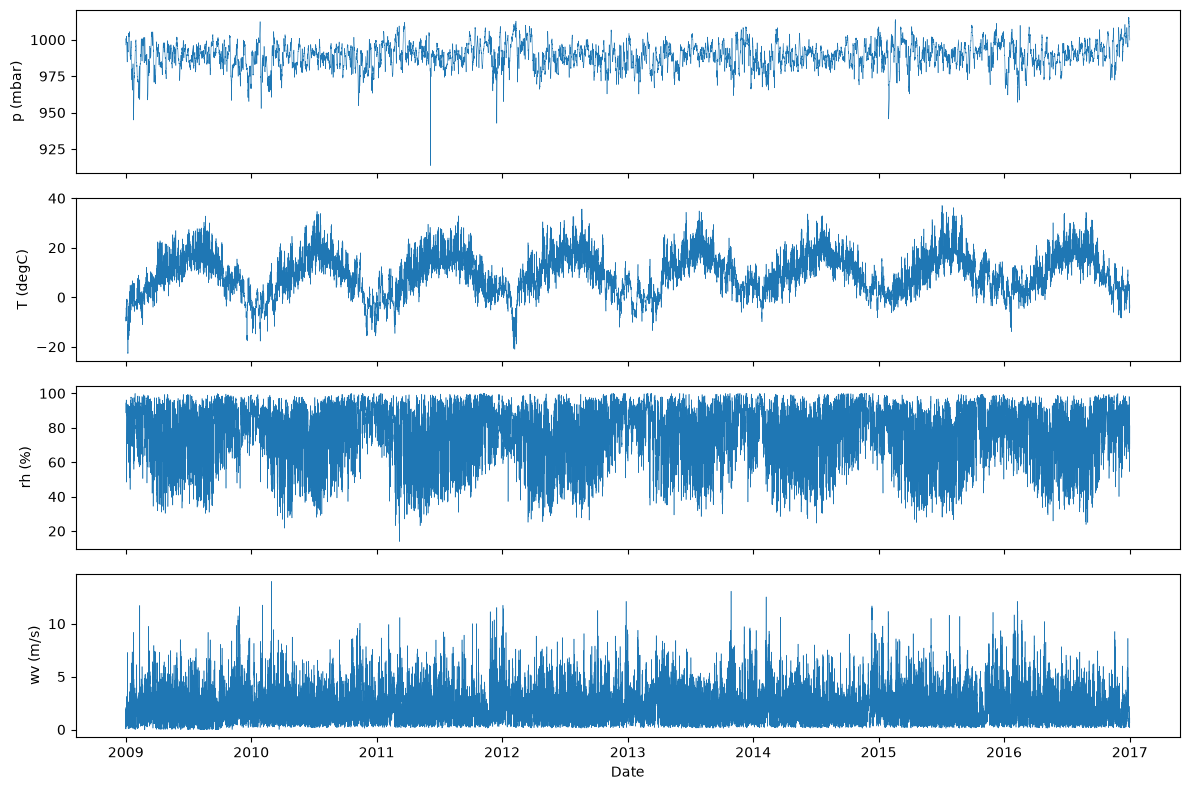

In [13]:
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(df["Date Time"], df[c], linewidth=0.4)
    ax.set_ylabel(c)
axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

the plots look like there are sitll some extremeties. Look at the atmospheric pressure, it has a shap spike to a low pressure. We can then plot in a closer look up to see if it was a sensor glitch or the data is legit. Also the other data seem to within good ranges, so no need to investigate.

In [15]:
checks = {
    "T (degC)": df["T (degC)"] < -30, #values found online/common sense indicating lowest mean temperature for that region in germany
    "p (mbar)": df["p (mbar)"] < 950,
    "rh (%)":   df["rh (%)"] < 5,
    "wv (m/s)": df["wv (m/s)"] > 20,
}
for name, mask in checks.items():
    print(f"{name}: {mask.sum()} rows flagged")
    print(df.loc[mask, ["Date Time", "p (mbar)", "T (degC)", "rh (%)", "wv (m/s)"]].head(20))
    print()

T (degC): 0 rows flagged
Empty DataFrame
Columns: [Date Time, p (mbar), T (degC), rh (%), wv (m/s)]
Index: []

p (mbar): 31 rows flagged
                Date Time  p (mbar)  T (degC)  rh (%)  wv (m/s)
541   2009-01-23 14:00:00    947.77      0.52    90.3      8.90
542   2009-01-23 15:00:00    946.05      1.55    86.2      9.19
543   2009-01-23 16:00:00    945.13      2.00    86.5      7.77
544   2009-01-23 17:00:00    944.88      3.64    84.8      6.22
545   2009-01-23 18:00:00    944.99      4.79    81.2      6.46
546   2009-01-23 19:00:00    945.96      5.40    78.4      5.58
547   2009-01-23 20:00:00    946.90      5.10    80.3      4.47
548   2009-01-23 21:00:00    948.43      5.68    78.9      3.74
549   2009-01-23 22:00:00    949.80      5.34    77.7      4.33
21276 2011-06-06 13:20:00    913.60     25.11    53.7      3.59
25906 2011-12-16 11:20:00    949.88      3.24    85.1      8.78
25907 2011-12-16 12:20:00    947.13      3.64    83.9      5.67
25908 2011-12-16 13:20:00    94

lets observe closer to there timestamps

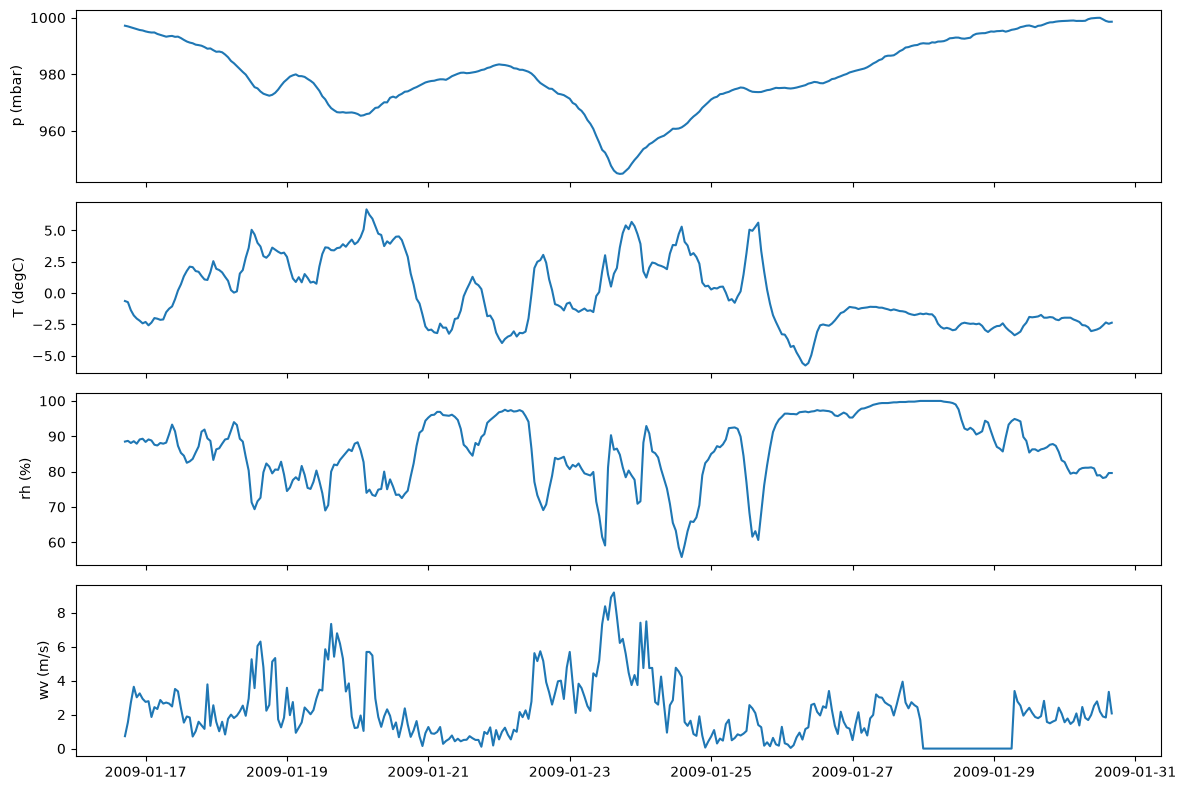

In [17]:
# zoom into to see if temperature was wrong to see the daily pattern
week = df.iloc[544-24*7:544+24 * 7]
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

Smooth data, looks good

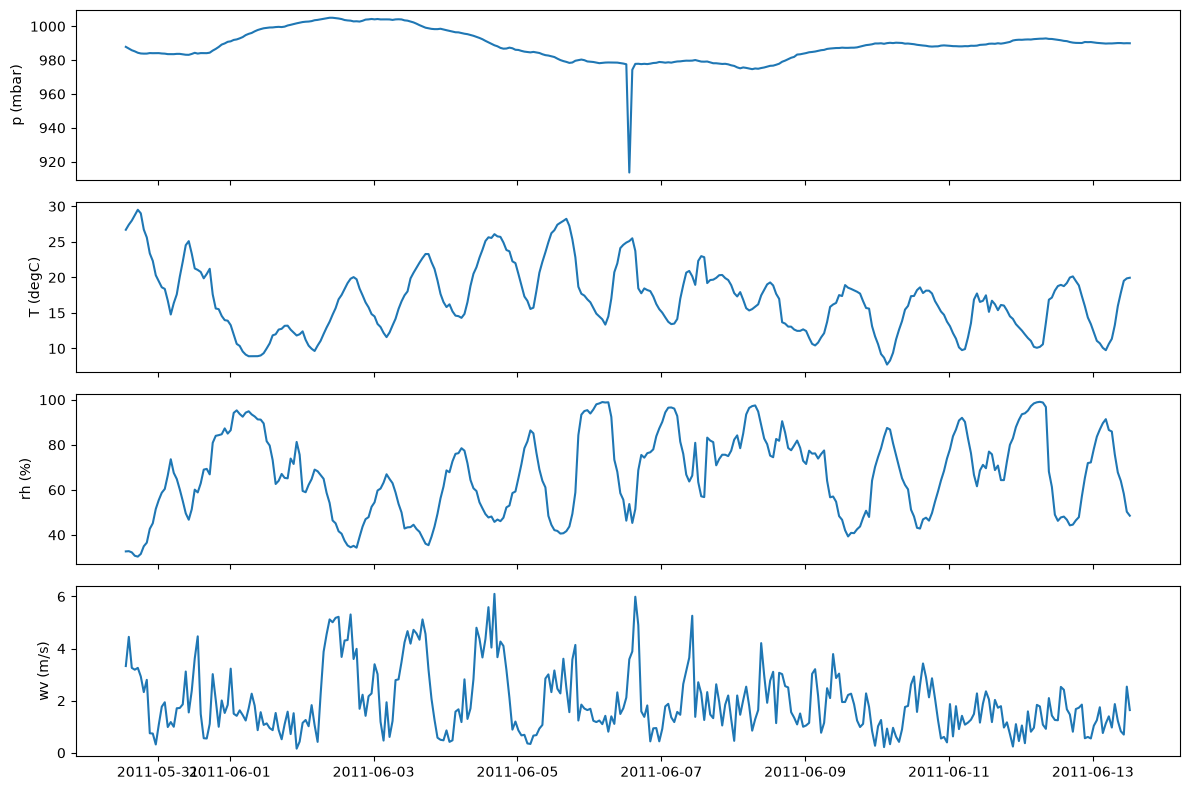

In [18]:
week = df.iloc[21276 -24*7:21276 +24 * 7] # before and after a week
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

seems like a sensor error, lets reject this point

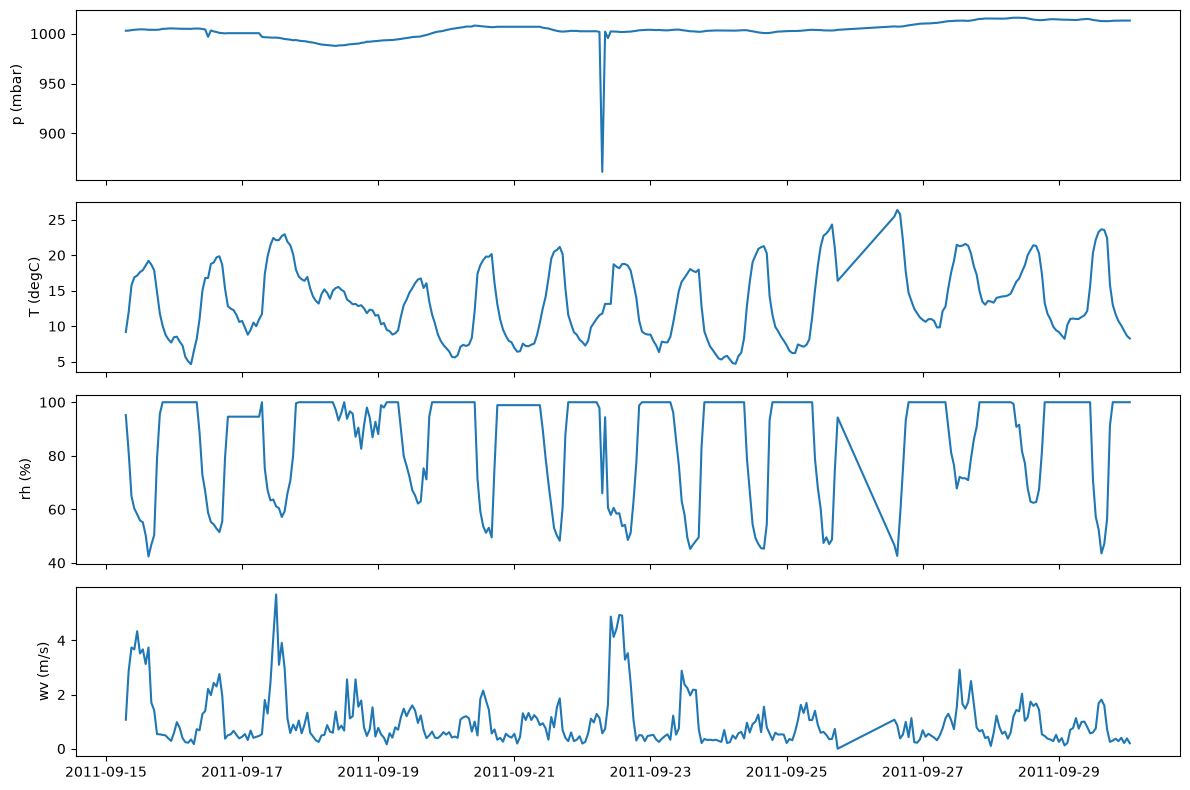

In [120]:
# zoom into to see if atmos pressure was wrong to see the daily pattern
week = df.iloc[23759 - 24*7:23759 +24 * 7]
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

clearly a glitch, we remove it

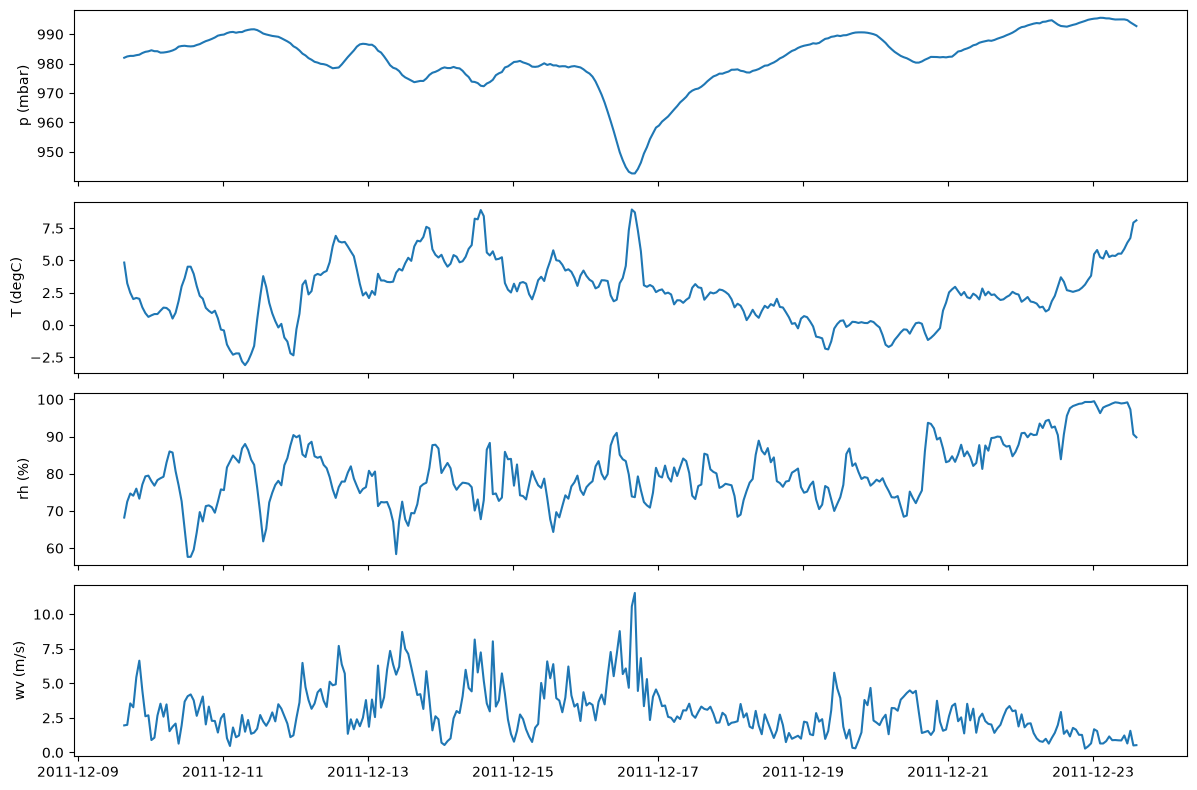

In [19]:
week = df.iloc[25910 - 24*7:25910 +24 * 7]
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

looks smooth enough. we keep this data

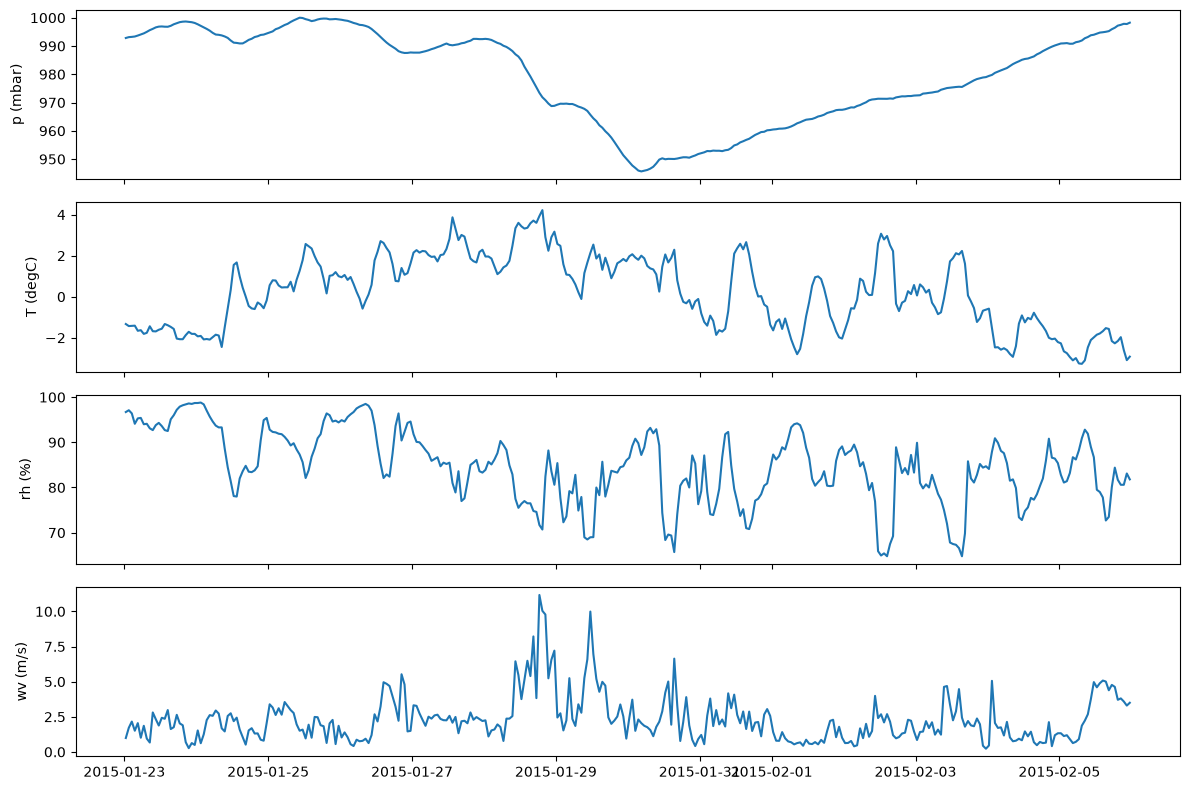

In [21]:
week = df.iloc[53263 - 7*24:53263 +7*24]
fig, axes = plt.subplots(len(target_cols), 1, figsize=(12, 8), sharex=True)
for ax, c in zip(axes, target_cols):
    ax.plot(week["Date Time"], week[c])
    ax.set_ylabel(c)
plt.tight_layout()
plt.show()

Smooth change. That is normal.

in the end we only discard one sensor data at timestamp 21276